In [1]:
# Run these small tutorials on CPU; select a GPU before importing JAX for larger runs.
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import jax
import jax.numpy as jnp
import numpy as np
import marlax as mx
from marlax.envs import CooperativeGrid, GridState
from marlax.models import QTable
from marlax.methods import QLearning, SARSA, ExpectedSARSA


In [2]:
# 1. The low-level runner exposes state so custom experiments can control chunks.
env = CooperativeGrid()
params = env.default_params()
agent = mx.Agent(QTable())
method = QLearning(epsilon_steps=1024)
state = mx.initialize(env, params, agent, method, seed=0, num_envs=32)
advance = jax.jit(lambda state: mx.run_steps(env, params, method, state, num_steps=16))
state, statistics = advance(state)
state, statistics = advance(state)
assert int(state.method_state.env_steps) == 1024
{"world_transitions": int(state.method_state.env_steps), "updates": int(state.method_state.updates),
 "mean_reward_per_step": float(statistics["reward_per_step"].mean())}


{'world_transitions': 1024,
 'updates': 32,
 'mean_reward_per_step': -0.013125002384185791}

In [3]:
# 2. Load the included policy and inspect the metrics returned by evaluate.
# Start the notebook with its own directory as the working directory.
from pathlib import Path
root = Path.cwd().parents[2]
with np.load(root / "stores/coop_grid_q_learning/latest/q_values.npz", allow_pickle=False) as saved:
    policy = mx.FrozenPolicy(mx.Agent(QTable()), jnp.asarray(saved["q"]))
report = mx.evaluate(policy, env, params, initial_states=env.all_starts(), max_steps=params.time_limit)
report


{'cases': 3750,
 'mean_return': 1.148703932762146,
 'mean_episode_steps': 5.1296,
 'termination_rate': 1.0,
 'truncation_rate': 0.0,
 'unfinished_rate': 0.0,
 'activated_rate': 1.0,
 'wrong_target_rate': 0.0,
 'collected_rate': 1.0}

In [4]:
# 3. Forward simulation needs only the frozen policy and environment.
# Keep terminal positions for inspection; the environment never resets implicitly.
state = GridState(jnp.array([[1, 0], [3, 4]]), jnp.array(0), jnp.array(False), jnp.array(0))
path = [np.asarray(state.positions)]
key = jax.random.PRNGKey(10)
for _ in range(params.time_limit):
    key, act_key, step_key = jax.random.split(key, 3)
    decision = policy.act(env.observe(state, params), (), act_key)
    state, timestep = env.step(step_key, state, decision.actions, params)
    path.append(np.asarray(state.positions))
    if timestep.terminated | timestep.truncated:
        break
path = np.stack(path)
{"steps": len(path) - 1, "final_positions": path[-1]}


{'steps': 5,
 'final_positions': array([[4, 2],
        [4, 2]], dtype=int32)}

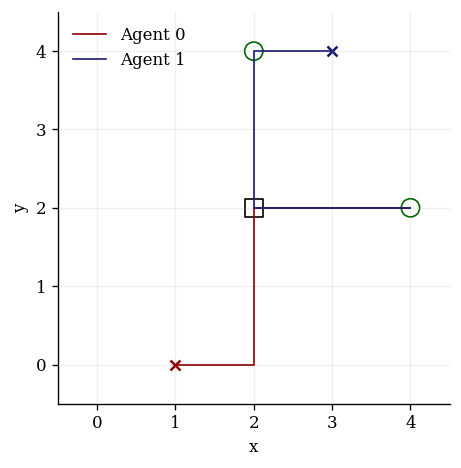

In [5]:
# 4. Plot the saved policy's trajectory; rendering does not affect dynamics.
import matplotlib.pyplot as plt
with plt.rc_context({"font.family": "serif", "mathtext.fontset": "cm"}):
    fig, ax = plt.subplots(figsize=(4, 4), dpi=120)
    for i, color in enumerate(("darkred", "midnightblue")):
        ax.plot(path[:, i, 0], path[:, i, 1], color=color, linewidth=1, label=f"Agent {i}")
        ax.scatter(*path[0, i], marker="x", color=color)
    ax.scatter(*np.asarray(env.center), marker="s", facecolors="none", edgecolors="black", s=120)
    targets = np.asarray(env.targets[0])
    ax.scatter(targets[:, 0], targets[:, 1], marker="o", facecolors="none", edgecolors="darkgreen", s=120)
    ax.set(xlim=(-0.5, 4.5), ylim=(-0.5, 4.5), xticks=range(5), yticks=range(5),
           aspect="equal", xlabel="x", ylabel="y")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()
